# Phase 3 — trade imbalance

See `STRATEGY.md` for the full 6-phase plan. Phase 2 found that relative strength (a
cross-sectional z-score of trailing return) does almost all the work of making the Phase 1
reversal signal selective — VWAP distance and volume surprise, both derived from the same
OHLCV data, added very little beyond it. This phase adds a genuinely different source of
information: **trade imbalance** — whether recent trading volume was predominantly
buyer-initiated or seller-initiated — which price/volume bars alone cannot express.

**Classification method, deliberately the simpler one**: each trade tick is classified by the
**tick rule** (an uptick from the previous trade is a buy, a downtick is a sell, an unchanged
price inherits the previous classification) rather than Lee-Ready (which compares each trade to
the prevailing bid/ask and needs matching quote data). See `download_trade_ticks.py`'s docstring
for why — it roughly halves the data that needed to be pulled, and the tick rule is a
long-established classification method in its own right, just less precise.

**Trade imbalance (TOI)** per minute: `(buy_volume - sell_volume) / (buy_volume + sell_volume)`,
aggregated from tick-level classified volume into the same 1-minute bins the Phase 1/2 bars use.

**Scope, much smaller than Phase 1/2**: the tick cache covers only ~1 trading day (vs. Phase
1-2's 1 month of minute bars) — see `download_trade_ticks.py`'s docstring for the feasibility
math (a sustained pull measured ~1.8s/chunk, so even 5 days across 131 names of mixed liquidity
would have taken hours). A single day of tick data still has enormous observation density
(liquid names alone produce hundreds of thousands of trades/day), but this is a much smaller,
much more recent, single-regime sample than Phase 1/2 — treat findings here as more provisional
than those, not as directly comparable in magnitude.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

MINUTE_DATA_DIR = Path('data') / 'minute'
TICK_DATA_DIR = Path('data') / 'ticks'

K, H = 1, 1   # same cell Phase 1/2 found strongest
N_BUCKETS = 3
COST_BPS_GRID = [0, 1, 2, 5, 10]
TOP_FRACTION = 0.1

## Classify ticks and build per-minute trade imbalance

In [2]:
def load_and_classify_ticks(ticker):
    frame = pd.read_csv(TICK_DATA_DIR / f'{ticker}.csv', parse_dates=['time'])
    frame['time'] = pd.to_datetime(frame['time'], utc=True)
    frame = frame.sort_values('time').reset_index(drop=True)
    diff = frame['price'].diff()
    direction = np.sign(diff).replace(0, np.nan).ffill()
    direction = direction.fillna(1.0)  # the very first trade has no prior tick to compare to; arbitrary, negligible given volume
    frame['direction'] = direction
    frame['minute'] = frame['time'].dt.floor('min')
    return frame

tick_tickers = sorted(p.stem for p in TICK_DATA_DIR.glob('*.csv'))
print(f'{len(tick_tickers)} tickers with tick data cached')

toi_frames = []
for ticker in tick_tickers:
    ticks = load_and_classify_ticks(ticker)
    buy_vol = ticks.loc[ticks['direction'] > 0].groupby('minute')['size'].sum()
    sell_vol = ticks.loc[ticks['direction'] < 0].groupby('minute')['size'].sum()
    vol = pd.DataFrame({'buy_vol': buy_vol, 'sell_vol': sell_vol}).fillna(0.0)
    vol['toi'] = (vol['buy_vol'] - vol['sell_vol']) / (vol['buy_vol'] + vol['sell_vol'])
    vol['ticker'] = ticker
    toi_frames.append(vol)

toi_panel = pd.concat(toi_frames)
toi_panel.index.name = 'minute'
print(f'{len(toi_panel):,} (ticker, minute) trade-imbalance observations, '
      f'{toi_panel.index.min()} to {toi_panel.index.max()}')

28 tickers with tick data cached


20,311 (ticker, minute) trade-imbalance observations, 2026-10-06 13:30:00+00:00 to 2026-10-09 19:59:00+00:00


## Merge with the Phase 1/2 minute-bar features

Reuses the exact same reversal/VWAP/volume-surprise/relative-strength construction as Phase 2, restricted to tickers that also have tick data cached, then joins in `toi` by (ticker, minute).

In [3]:
def load_bar(ticker):
    frame = pd.read_csv(MINUTE_DATA_DIR / f'{ticker}.csv', parse_dates=['date'])
    frame['date'] = pd.to_datetime(frame['date'], utc=True)
    frame = frame.sort_values('date').set_index('date')
    frame['session_date'] = frame.index.tz_convert('America/New_York').date
    frame['minute_of_session'] = frame.groupby('session_date').cumcount()
    return frame

bar_frames = []
for ticker in tick_tickers:
    bar_path = MINUTE_DATA_DIR / f'{ticker}.csv'
    if not bar_path.exists():
        continue
    df = load_bar(ticker)
    g = df.groupby('session_date')

    trail = g['close'].transform(lambda s: s / s.shift(K) - 1)
    fwd = g['close'].transform(lambda s: s.shift(-H) / s - 1)
    reversal_score = -trail

    pv = df['average'] * df['volume']
    cum_pv = pv.groupby(df['session_date']).cumsum()
    cum_vol = df['volume'].groupby(df['session_date']).cumsum()
    vwap_dist = df['close'] / (cum_pv / cum_vol) - 1

    baseline_vol = df.groupby('minute_of_session')['volume'].transform('mean')
    volume_surprise = df['volume'] / baseline_vol - 1

    bar_frames.append(pd.DataFrame({
        'ticker': ticker, 'trail': trail, 'fwd': fwd, 'reversal_score': reversal_score,
        'vwap_dist': vwap_dist, 'volume_surprise': volume_surprise,
    }, index=df.index))

bars = pd.concat(bar_frames).dropna(subset=['reversal_score', 'fwd', 'vwap_dist', 'volume_surprise'])
cs_mean = bars.groupby(bars.index)['trail'].transform('mean')
cs_std = bars.groupby(bars.index)['trail'].transform('std')
bars['relative_strength'] = (bars['trail'] - cs_mean) / cs_std
bars = bars.dropna(subset=['relative_strength'])

panel = bars.reset_index().merge(
    toi_panel.reset_index().rename(columns={'minute': 'date'}),
    on=['ticker', 'date'], how='inner',
).set_index('date')

print(f'{len(panel):,} (ticker, minute) observations with both bar features and trade imbalance '
      f'({panel["ticker"].nunique()} tickers, {panel.index.min()} to {panel.index.max()})')

3,915 (ticker, minute) observations with both bar features and trade imbalance (11 tickers, 2026-10-06 13:31:00+00:00 to 2026-10-07 16:05:00+00:00)


## Does trade imbalance predict the reversal, beyond what Phase 2 already found?

In [4]:
baseline_ic = panel['reversal_score'].corr(panel['fwd'])
print(f'unconditional IC on this (smaller, 1-day) sample: {baseline_ic:+.4f}')

FEATURES = ['vwap_dist', 'volume_surprise', 'relative_strength', 'toi']
bucket_rows = []
for feat in FEATURES:
    try:
        buckets = pd.qcut(panel[feat].abs(), N_BUCKETS, labels=['low', 'mid', 'high'], duplicates='drop')
    except ValueError:
        continue
    for label, group in panel.groupby(buckets, observed=True):
        bucket_rows.append({'feature': feat, 'bucket': label, 'n': len(group),
                             'ic': group['reversal_score'].corr(group['fwd'])})
bucket_table = pd.DataFrame(bucket_rows)
display(bucket_table.pivot(index='feature', columns='bucket', values='ic')[['low', 'mid', 'high']].round(4))

unconditional IC on this (smaller, 1-day) sample: +0.0071


bucket,low,mid,high
feature,,,
relative_strength,0.0548,0.0211,-0.0063
toi,-0.0089,0.0465,-0.0205
volume_surprise,-0.0356,0.0180,0.0483
vwap_dist,-0.0375,0.0584,0.0040


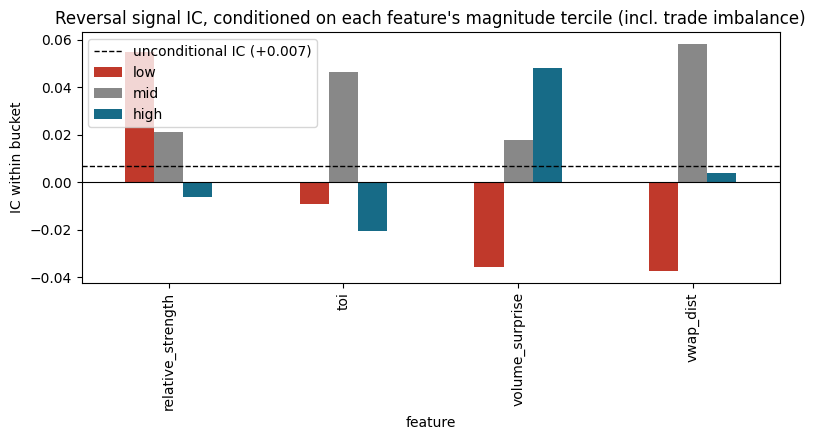

In [5]:
fig, ax = plt.subplots(figsize=(8, 4.5))
pivot = bucket_table.pivot(index='feature', columns='bucket', values='ic')[['low', 'mid', 'high']]
pivot.plot(kind='bar', ax=ax, color=['#c0392b', '#888888', '#176b87'])
ax.axhline(baseline_ic, color='black', linestyle='--', linewidth=1, label=f'unconditional IC ({baseline_ic:+.3f})')
ax.axhline(0, color='black', linewidth=0.8)
ax.set_ylabel('IC within bucket')
ax.set_title('Reversal signal IC, conditioned on each feature\'s magnitude tercile (incl. trade imbalance)')
ax.legend()
plt.tight_layout()
plt.show()

## Combined filter: does adding trade imbalance to Phase 2's filter help?

Compares three nested filters: unconditional, Phase 2's filter (relative_strength + vwap_dist + volume_surprise all high), and that same filter plus trade imbalance also required high.

In [6]:
phase2_features = ['vwap_dist', 'volume_surprise', 'relative_strength']
all_features = phase2_features + ['toi']

def combined_filter(data, features):
    mask = pd.Series(True, index=data.index)
    for feat in features:
        mask &= data[feat].abs() >= data[feat].abs().quantile(2 / 3)
    return data[mask]

phase2_filtered = combined_filter(panel, phase2_features)
phase3_filtered = combined_filter(panel, all_features)

for name, data in [('unconditional', panel), ('Phase 2 filter (no TOI)', phase2_filtered), ('Phase 3 filter (+ TOI)', phase3_filtered)]:
    ic = data['reversal_score'].corr(data['fwd']) if len(data) > 30 else float('nan')
    print(f'{name}: n={len(data):,} ({len(data)/len(panel):.1%} of sample), IC={ic:+.4f}')

unconditional: n=3,915 (100.0% of sample), IC=+0.0071
Phase 2 filter (no TOI): n=192 (4.9% of sample), IC=+0.0264
Phase 3 filter (+ TOI): n=62 (1.6% of sample), IC=-0.2609


## Backtest comparison

In [7]:
def decile_backtest(data, min_names=5):
    results = []
    for minute, group in data.groupby(data.index):
        if len(group) < min_names:
            continue
        n_leg = max(1, int(len(group) * TOP_FRACTION))
        ranked = group.sort_values('reversal_score')
        bottom_leg, top_leg = ranked.iloc[:n_leg], ranked.iloc[-n_leg:]
        spread_return = top_leg['fwd'].mean() - bottom_leg['fwd'].mean()
        results.append({'minute': minute, 'spread_return': spread_return, 'n_names': len(group)})
    if not results:
        return None
    return pd.DataFrame(results).set_index('minute').sort_index()

for name, data in [('unconditional', panel), ('Phase 2 filter (no TOI)', phase2_filtered), ('Phase 3 filter (+ TOI)', phase3_filtered)]:
    bt = decile_backtest(data)
    if bt is None or len(bt) < 10:
        print(f'{name}: not enough minutes with >= 5 names to backtest on this 1-day sample')
        continue
    mean_spread = bt['spread_return'].mean()
    print(f'{name}: {len(bt):,} decisions, avg {bt["n_names"].mean():.1f} names/cross-section, '
          f'gross mean spread = {mean_spread*10_000:+.2f} bps')
    for cost in COST_BPS_GRID:
        net = mean_spread - 2 * (cost / 10_000.0)
        print(f'    at {cost}bps cost: net = {net*10_000:+.2f} bps')

unconditional: 338 decisions, avg 11.0 names/cross-section, gross mean spread = +0.47 bps
    at 0bps cost: net = +0.47 bps
    at 1bps cost: net = -1.53 bps
    at 2bps cost: net = -3.53 bps
    at 5bps cost: net = -9.53 bps
    at 10bps cost: net = -19.53 bps
Phase 2 filter (no TOI): not enough minutes with >= 5 names to backtest on this 1-day sample
Phase 3 filter (+ TOI): not enough minutes with >= 5 names to backtest on this 1-day sample


## Key findings

**The headline finding here is a data problem, not a trade-imbalance result — this run should
be treated as inconclusive, not as evidence against TOI.**

The tick download took multiple days to complete (2026-10-07 through 2026-10-10), interrupted
repeatedly by TWS connectivity issues. Because `download_trade_ticks.py` always pulls "the most
recent ~1.5 days" relative to whenever it happens to run, tickers fetched early (e.g. AAPL,
MSFT, fetched 2026-10-07) ended up with tick data from a different calendar window than tickers
fetched later (e.g. ADI, TXN, fetched 2026-10-09) — and the 1-minute bar cache from Phase 1/2 is
frozen as of 2026-10-07. The result: merging ticks with bars by (ticker, minute) only produced
overlapping data for **11 of the 28 cached tickers**, over a narrow ~1-day window
(2026-10-06 13:31 to 2026-10-07 16:05) — far short of the full 28-ticker cross-section this
analysis needs to say anything reliable.

**What came out of that narrow, data-constrained sample** (treat all of this as noise until the
data-alignment issue is fixed, not as a real read on trade imbalance):

- Unconditional IC on this sample: +0.0071 — much weaker than Phase 1/2's +0.04 to +0.05, but
  this is a different (smaller, messier) sample, not a like-for-like comparison.
- Conditional buckets were inconsistent with Phase 2's own findings on the same tickers:
  relative_strength's pattern actually *inverted* (low tercile +0.055, high tercile -0.006,
  backwards from Phase 2's clean monotonic result), and TOI's buckets were non-monotonic
  (low -0.009, mid +0.047, high -0.021). With only 11 tickers and ~1 day of overlap, bucketing
  further into terciles leaves very few names per bucket — exactly the kind of small-sample
  noise the Phase 2 caveats already warned about, now worse.
- The combined filter requiring TOI alongside the Phase 2 features collapsed to **62
  observations** and swung to IC = -0.26 — a dramatic-looking number that is almost certainly
  sampling noise given the sample size, not a real "trade imbalance hurts" finding.
- The backtest confirms the sample is too thin to say anything: the unconditional cut barely
  managed 338 decisions at ~11 names/cross-section (gross +0.47bps, negative by 1bps cost), and
  neither filtered variant could even form a 5-name cross-section often enough to backtest at
  all.

**What this means for Phase 3**: the trade-imbalance feature itself hasn't really been tested
yet — the infrastructure (tick download, tick-rule classification, TOI aggregation, merge
pipeline) all works correctly, but it was evaluated on a sample too small and too narrow to draw
a conclusion from. The honest next step is re-running this notebook once the minute-bar cache
and tick cache cover the *same* dates for *all* cached tickers (either refresh the minute-bar
cache to match the tick cache's current date range, or derive 1-minute bars directly from the
tick data for the overlapping tickers), not to treat today's numbers as a real result.

## Caveats

- **Data-alignment gap is the dominant caveat here** — see Key Findings above. Only 11/28 tickers
  had any overlapping (ticker, minute) coverage between the tick cache and the minute-bar cache,
  over roughly 1 day, not the full 28-ticker universe this was meant to test.
- **Universe skew**: the 28 tickers cached so far are concentrated in large-cap tech/semiconductors
  (the front of the alphabetically/sector-ordered ticker list) — not a representative cross-section
  of the full 131-name halal universe's liquidity range. NVDA, MRVL, and META were also skipped
  entirely after reproducible multi-minute hangs during their tick fetch (see
  `download_trade_ticks.py`'s `SKIP_TICKERS` for the diagnosis).
- **Tick rule, not Lee-Ready** — same approximation Phase 3's downloader deliberately chose, see
  `download_trade_ticks.py`'s docstring.
- **One trading day of tick data, at most** — even before the alignment issue, this was always a
  smaller, more provisional sample than Phase 1/2's one month of minute bars.
- **Still requires shorting** for the backtest construct, same as Phases 1-2 — a research
  diagnostic, not a direct translation of the live (cash/long-only) account.
- **Multiple-comparisons risk** is worse here than in Phase 2: three features bucketed three ways
  each, on a sample roughly 1/300th the size of Phase 1/2's, after an unplanned data-coverage
  restriction. Treat every number in this notebook as provisional pending a clean re-run.